In [ ]:
pip install pennylane

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 53.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 937.5/937.5 kB 11.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.5/25.5 MB 58.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 28.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.9/7.9 MB 49.1 MB/s  0:00:00
  Attempting uninstall: autograd
    Found existing installation: autograd 1.9.1
    Uninstalling autograd-1.9.1:
      Successfully uninstalled autograd-1.9.1
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8/8 [pennylane]


In [ ]:
import pennylane as qml

In [ ]:
from pennylane import numpy as np
import matplotlib.pyplot as plt

In [ ]:
np.random.seed(42)
X=np.linspace(-np.pi, np.pi, 100)
y= np.sin(X)+ 0.3*np.cos(2*X)

y_noisy= y + 0.05*np.random.randn(len(X))

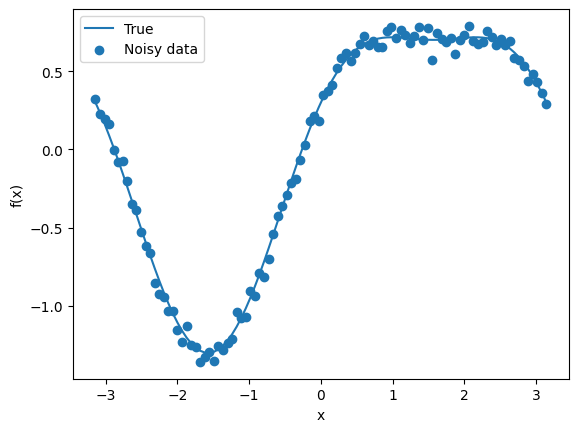

In [ ]:
plt.figure()
plt.plot(X,y,label="True")
plt.scatter(X, y_noisy,  label="Noisy data")

plt.xlabel("x")
plt.ylabel("f(x)")

plt.legend()
plt.show()

In [ ]:
n_qubits=2
n_layers=3
dev=qml.device("default.qubit", wires=n_qubits)

In [ ]:
@qml.qnode(dev)
def circuit(x, weights):
  for layer in range(n_layers):
    qml.RY(x, wires=0)
    qml.RY(2*x, wires=1)

    for wire in range(n_qubits):
      qml.Rot(*weights[layer, wire], wires=wire)

    qml.CNOT(wires=[0,1])

    return (

            qml.expval(qml.PauliX(0)), qml.expval(qml.PauliZ(1))
    )



In [ ]:
weights=np.random.normal(0,0.1, size=(n_layers, n_qubits, 3), requires_grad=True)

readout= np.array([0.5,0.5], requires_grad=True) ###a0, a1

bias= np.array(0.0, requires_grad=True)



In [ ]:
def model(x, weights, readout, bias):
  q0, q1=circuit(x, weights)
  return (readout[0]*q0  +  readout[1]*q1  + bias)


In [ ]:
def loss(weights, readout, bias):

  predictions=[]
  for x in X:
    predictions.append(model(x, weights, readout, bias))

  predictions = np.array(predictions)

  return np.mean((predictions - y_noisy)**2)

In [ ]:
opt= qml.AdamOptimizer(stepsize=0.01)

epochs=300

loss_history=[]

for epoch in range(epochs):
  weights, readout, bias = opt.step(loss, weights, readout, bias)

  current_loss= loss(weights, readout, bias)

  loss_history.append(current_loss)

  if (epoch+1) %50 == 0:
    print(f"Epoch: {epoch+1}, Loss: {current_loss}")

Epoch: 50, Loss: 0.36836106627858106
Epoch: 100, Loss: 0.059082811986949826
Epoch: 150, Loss: 0.04861452970385762
Epoch: 200, Loss: 0.04858276884344148
Epoch: 250, Loss: 0.04858269073863858
Epoch: 300, Loss: 0.048582689622577516


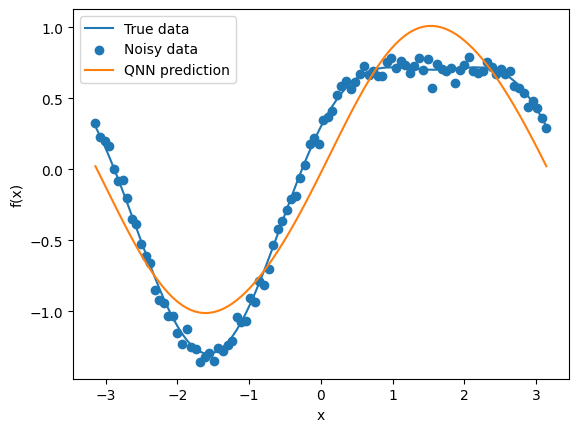

In [ ]:
y_pred=[]

for x in X:
  y_pred.append(model(x, weights, readout, bias))

y_pred=np.array(y_pred)

plt.figure()
plt.plot(X, y , label="True data")
plt.scatter(X, y_noisy, label= "Noisy data")
plt.plot(X, y_pred, label= "QNN prediction")

plt.xlabel( "x")
plt.ylabel( "f(x)")

plt.legend()
plt.show()

In [ ]:
readout

tensor([1.02634852, 0.99581337], requires_grad=True)